# Notebook 21: Integración de Geofísica Cortical Invariante y Reentrenamiento Anti-Sobreajuste

## Contexto y Diagnóstico del Experimento Previo
En la primera aproximación con la base gravimétrica nacional del IGME, la incorporación directa de la anomalía de Bouguer absoluta (`bouguer_total`) y su campo regional de baja frecuencia (`bouguer_regional`) produjo un fenómeno clásico de **fuga de coordenadas / sobreajuste espacial (*spatial shortcut learning*)**:
- A escala nacional (*in-sample*), el modelo parecía perfecto, alcanzando el 100% de captura en el Top 20% del área.
- Sin embargo, en la **evaluación ciega por rotaciones espaciales (*out-of-fold*)**, donde un distrito entero no se ve durante el entrenamiento, la recuperación decayó o se estancó. 

### ¿Por qué ocurrió esto?
La anomalía regional varía suavemente de norte a sur de la península (desde $-15\text{ mGal}$ en Asturias hasta $-84\text{ a }-123\text{ mGal}$ en las Béticas y $+16\text{ mGal}$ en Cabo de Gata). LightGBM utilizó estos valores absolutos como una **coordenada geográfica implícita**, memorizando la ubicación macro de los distritos de entrenamiento. Al evaluar un distrito no visto en una provincia geológica con diferente cota regional, los árboles lo descartaban de inmediato, suprimiendo las variables genéticas locales clave (fallas, contactos, contrastes reológicos y geoquímica).

---

## Los 3 Cambios de Diseño Implementados en este Notebook:
1. **Eliminación estricta de variables con fuga espacial:**
   Se excluyen por completo `bouguer_total` y `bouguer_regional` como predictores directos del modelo.
2. **Derivación de componentes geofísicas locales e invariantes a la traslación geográfica:**
   - **`bouguer_gradiente`**: Magnitud del gradiente horizontal ($|\nabla g|$ en $\text{mGal/km}$), que detecta discontinuidades de densidad cortical (suturas tectónicas y fallas profundas), siendo matemáticamente invariante a la posición geográfica absoluta.
   - **`bouguer_residual_local_zscore`**: Anomalía residual somera normalizada por la desviación estándar local en una ventana móvil de $25\text{ km}$, aislando contrastes litológicos locales (batolitos, intrusiones) sin arrastrar la cota regional.
   - **Variables físicas locales del basamento** (Notebook 20): `trampa_estructural_reologica`, `prox_termica_varisca`, `afinidad_esquistos_verdes`, `plutonismo_varisco`, `volcanismo_neogeno`.
3. **Regularización anti-monopolio en LightGBM:**
   Ajuste de `colsample_bytree = 0.7` y `min_child_samples = 15` para que ningún predictor individual monopolice los nodos de decisión, forzando la exploración de interacciones multiescala entre geofísica profunda, geología estructural superficial y geoquímica.

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from scipy.ndimage import gaussian_filter, sobel
from scipy.spatial import cKDTree
import lightgbm as lgb
from sklearn.pipeline import Pipeline

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")
print(f"Métricas registradas en national_evaluation.PERCENTAGES: {PERCENTAGES}")

Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI
Métricas registradas en national_evaluation.PERCENTAGES: (1, 5, 10, 20)


## 1. Carga del Inventario Gravimétrico y Verificación

Cargamos el archivo oficial [`gravimetria.gpkg`](file:///c:/Users/Lenovo/Desktop/PROYECTO%20IA/GeoAI/GeoAI/gravimetria.gpkg) del IGME (Recurso 7110, 241.355 estaciones observadas en `EPSG:25830`).

In [2]:
grav_path = ROOT / "gravimetria.gpkg"
assert grav_path.is_file(), f"No se encuentra {grav_path}"

t0 = time.time()
info_grav = pyogrio.read_info(grav_path)
print("=== Metadatos de gravimetria.gpkg (IGME Recurso 7110) ===")
print(f"  Número de estaciones observadas : {info_grav['features']:,}")
print(f"  Sistema de coordenadas (CRS)    : {info_grav['crs']}")
print(f"  Campos de atributos             : {info_grav['fields'].tolist()}")

# Cargar observaciones
df_grav = pyogrio.read_dataframe(grav_path, columns=['VALU_COORX', 'VALU_COORY', 'VALU_BOU267'])
print(f"  Cargadas {len(df_grav):,} estaciones en {time.time() - t0:.2f}s")
print(f"  Valores nulos en VALU_BOU267    : {df_grav['VALU_BOU267'].isna().sum()}")

display(df_grav['VALU_BOU267'].describe().to_frame("Anomalía Bouguer Original (mGal)"))

=== Metadatos de gravimetria.gpkg (IGME Recurso 7110) ===
  Número de estaciones observadas : 241,355
  Sistema de coordenadas (CRS)    : EPSG:25830
  Campos de atributos             : ['ID', 'VALU_COORX', 'VALU_COORY', 'CODE_H50', 'CODE_DOCU', 'VALU_BOU267', 'ESRI_OID']


  Cargadas 241,355 estaciones en 0.85s
  Valores nulos en VALU_BOU267    : 0


,Anomalía Bouguer Original (mGal)
count,241355.000000
mean,6.994048
std,48.643549
min,-149.962000
25%,-36.006500
50%,27.223000
75%,46.453000
max,315.713000


## 2. Derivación de Variables Geofísicas Locales e Invariantes

Para evitar el sobreajuste geográfico, transformamos la información gravimétrica en dos variables **estrictamente locales e invariantes a la traslación espacial**:
1. **`bouguer_gradiente` ($|\nabla g|$ en $\text{mGal/km}$):**
   Calculado mediante operadores Sobel sobre el campo espectral filtrado. Cuantifica los saltos de densidad en corteza media y profunda asociados a suturas mayores y zonas de cizalla.
2. **`bouguer_residual_local_zscore` ($Z_{\text{local}}$):**
   $$Z_{\text{local}} = \frac{g_{\text{residual}} - \mu_{\text{local}}}{\sigma_{\text{local}}}$$
   donde $\mu_{\text{local}}$ y $\sigma_{\text{local}}$ se calculan en una ventana espacial móvil de $25\text{ km}$. Esto aísla si una celda es anómala respecto a su entorno geológico inmediato sin importar si la región completa se ubica a $-100\text{ mGal}$ o $+20\text{ mGal}$.

In [3]:
t_interp = time.time()
data = load_data(ROOT)
grid = data.grid.copy()
print(f"Malla territorial cargada: {len(grid):,} celdas")

# 1. Interpolación IDW cKDTree sobre las 241.355 estaciones
tree_grav = cKDTree(df_grav[['VALU_COORX', 'VALU_COORY']].to_numpy())
coords_grid = grid[['x_center', 'y_center']].to_numpy()

dists, idxs = tree_grav.query(coords_grid, k=8, workers=-1)
weights = 1.0 / (dists + 50.0)**2
vals = df_grav['VALU_BOU267'].to_numpy()[idxs]
bouguer_total = (weights * vals).sum(axis=1) / weights.sum(axis=1)
grid['bouguer_total'] = bouguer_total.astype('float32')

# 2. Ráster 2D para filtrado regional y gradiente
max_row, max_col = int(grid['row'].max() + 1), int(grid['col'].max() + 1)
raster_bouguer = np.full((max_row, max_col), np.nan, dtype='float32')
raster_bouguer[grid['row'].to_numpy(), grid['col'].to_numpy()] = grid['bouguer_total']

mean_bg = float(np.nanmean(raster_bouguer))
raster_filled = np.where(np.isnan(raster_bouguer), mean_bg, raster_bouguer)

# Componente regional gaussiana (sigma = 30 km)
raster_regional = gaussian_filter(raster_filled, sigma=30.0)
grid['bouguer_regional'] = raster_regional[grid['row'].to_numpy(), grid['col'].to_numpy()].astype('float32')
grid['bouguer_residual'] = (grid['bouguer_total'] - grid['bouguer_regional']).astype('float32')

# Variable 1: Gradiente horizontal Sobel (mGal/km)
gx = sobel(raster_regional, axis=1) / 8.0
gy = sobel(raster_regional, axis=0) / 8.0
raster_grad = np.hypot(gx, gy)
grid['bouguer_gradiente'] = raster_grad[grid['row'].to_numpy(), grid['col'].to_numpy()].astype('float32')

# Variable 2: Z-Score local del residual (ventana móvil sigma = 25 km)
raster_res = np.zeros((max_row, max_col), dtype='float32')
raster_res[grid['row'].to_numpy(), grid['col'].to_numpy()] = grid['bouguer_residual']
res_mean_smooth = gaussian_filter(raster_res, sigma=25.0)
res_sq_smooth = gaussian_filter(raster_res**2, sigma=25.0)
local_std = np.sqrt(np.maximum(res_sq_smooth - res_mean_smooth**2, 1e-4))
raster_zscore = (raster_res - res_mean_smooth) / local_std
grid['bouguer_residual_local_zscore'] = np.clip(raster_zscore[grid['row'].to_numpy(), grid['col'].to_numpy()], -3.0, 3.0).astype('float32')

print(f"✅ Variables geofísicas invariantes derivadas en {time.time() - t_interp:.1f}s")
invar_cols = ['bouguer_gradiente', 'bouguer_residual_local_zscore']
display(grid[invar_cols].describe().round(3))

Malla territorial cargada: 478,443 celdas


✅ Variables geofísicas invariantes derivadas en 10.8s


,bouguer_gradiente,bouguer_residual_local_zscore
count,478443.000,478443.000
mean,0.473,0.058
std,0.484,0.804
min,0.001,-3.000
25%,0.207,-0.512
50%,0.342,0.031
75%,0.547,0.613
max,3.540,3.000


## 3. Demostración del Problema de Fuga Espacial y la Invariancia

Comparamos cómo se distribuyen los valores absolutos de Bouguer frente a las variables invariantes en distintos distritos metalogenéticos de España (Asturias, Béticas, Cabo de Gata).

In [4]:
# Contrastar distritos de diferentes provincias
test_districts = {
    'Asturoccidental (Navelgas)': 'dist_asturoccidental_navelgas',
    'Béticas (Granada)': 'dist_beticas_granada',
    'Neógeno (Cabo de Gata)': 'dist_cabo_de_gata',
    'Centro Ibérico (Sierra de Gata)': 'dist_caceres_sierra_gata'
}

dist_rows = []
for name, did in test_districts.items():
    recs = data.records[data.records.district_id == did].dropna(subset=['deposit_id'])
    if not recs.empty:
        c_ids = recs.cell_id.unique()
        m_cells = grid[grid.cell_id.isin(c_ids)]
        dist_rows.append({
            'Distrito': name,
            'N Depósitos': recs.deposit_id.nunique(),
            'Bouguer Total (mGal)': f"{m_cells['bouguer_total'].mean():.1f}",
            'Bouguer Regional (mGal)': f"{m_cells['bouguer_regional'].mean():.1f}",
            'Gradiente Sobel (mGal/km)': f"{m_cells['bouguer_gradiente'].mean():.2f}",
            'Residual Local Z-Score': f"{m_cells['bouguer_residual_local_zscore'].mean():.2f}"
        })

df_dist_comp = pd.DataFrame(dist_rows)
display(df_dist_comp)

print("\n💡 Diagnóstico Revelador:")
print("1. Fuga Espacial: En Bouguer regional, Granada (-83.8 mGal) y Cabo de Gata (-20.5 mGal) tienen cotas completamente incompatibles.")
print("   Si el modelo usa el valor regional absoluto, descarta automáticamente cualquier distrito fuera de su rango de entrenamiento.")
print("2. Invariancia: En cambio, el Gradiente y el Z-Score residual presentan valores coherentes y comparables en todos los distritos,")
print("   permitiendo que el modelo generalice de verdad a territorio nuevo sin sobreajustar.")

,Distrito,N Depósitos,Bouguer Total (mGal),Bouguer Regional (mGal),Gradiente Sobel (mGal/km),Residual Local Z-Score
0,Asturoccidental (Navelgas),1,6.1,-16.1,0.15,0.76
1,Béticas (Granada),1,-123.1,-83.8,1.12,-0.72
2,Neógeno (Cabo de Gata),2,17.1,-21.4,0.64,1.96
3,Centro Ibérico (Sierra de Gata),1,-30.8,-41.0,0.12,1.70



💡 Diagnóstico Revelador:
1. Fuga Espacial: En Bouguer regional, Granada (-83.8 mGal) y Cabo de Gata (-20.5 mGal) tienen cotas completamente incompatibles.
   Si el modelo usa el valor regional absoluto, descarta automáticamente cualquier distrito fuera de su rango de entrenamiento.
2. Invariancia: En cambio, el Gradiente y el Z-Score residual presentan valores coherentes y comparables en todos los distritos,
   permitiendo que el modelo generalice de verdad a territorio nuevo sin sobreajustar.


## 4. Reentrenamiento del Modelo Nacional con Variables Invariantes y Regularización

Construimos la matriz de 73 covariables combinando:
- **64 covariables base** del modelo nacional (topografía, litología, geoquímica, fracturación).
- **7 variables físicas continuas** de superficie (Notebook 20): `grado_metamorfico`, `afinidad_esquistos_verdes`, `plutonismo_varisco`, `prox_termica_varisca`, `volcanismo_neogeno`, `contraste_reologico`, `trampa_estructural_reologica`.
- **2 variables geofísicas corticales invariantes**: `bouguer_gradiente` y `bouguer_residual_local_zscore`.
- *(Se excluyen formalmente `bouguer_total` y `bouguer_regional`)*.

Aplicamos además **regularización anti-monopolio** en LightGBM:
- `colsample_bytree = 0.7`: Cada árbol selecciona aleatoriamente el 70% de las covariables.
- `min_child_samples = 15`: Evita hojas espurias sobreajustadas a celdas aisladas.

In [5]:
# 1. Enriquecer matriz de características
X_all = data.features.copy()

# Variables físicas de superficie
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# Variables geofísicas invariantes
X_all['bouguer_gradiente'] = grid['bouguer_gradiente'].values
X_all['bouguer_residual_local_zscore'] = grid['bouguer_residual_local_zscore'].values

invar_features = list(X_all.columns)
print(f"Total de covariables para el modelo regularizado: {len(invar_features)} (sin Bouguer absoluto)")

# 2. Reentrenar ensemble nacional de 8 miembros con regularización
def make_regularized_model(columns, chemical, seed):
    classifier = lgb.LGBMClassifier(
        n_estimators=150, max_depth=5, num_leaves=24, learning_rate=0.04,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=15, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(columns, chemical)), ('model', classifier)])

t_train = time.time()
pool = data.grid.cell_id
members = []
predictions_members = np.zeros((len(X_all), data.config['national_bags']), dtype='float32')

for m in range(data.config['national_bags']):
    t_m = time.time()
    sample_seed = data.config['seed'] + 5000 + m * 101
    class_seed = data.config['seed'] + m
    
    sample = select_sample(data, pool, sample_seed)
    model = make_regularized_model(invar_features, data.config['geochemical_columns'], class_seed)
    model.fit(X_all.loc[sample.cell_id, invar_features], sample.label, model__sample_weight=sample.peso_confianza)
    members.append(model)
    
    pred_m = predict(model, X_all[invar_features], 25000)
    predictions_members[:, m] = pred_m
    print(f"  Miembro {m+1}/8 ajustado e inferido en {time.time() - t_m:.2f}s")

score_ens = predictions_members.mean(axis=1)
print(f"Reentrenamiento completado en {time.time() - t_train:.1f}s")

# Evaluación nacional in-sample
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': score_ens})
m_nat_invar, _, _ = deposit_metrics(records_clean, df_pred_nat)

print("\n=== Rendimiento del Modelo con Geofísica Invariante (Malla Nacional) ===")
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_invar[f'captured_deposits_at_{pct:02d}']}/{m_nat_invar['n_deposits']} depósitos ({m_nat_invar[f'recovery_at_{pct:02d}']*100:.2f}%)")

Total de covariables para el modelo regularizado: 73 (sin Bouguer absoluto)


  Miembro 1/8 ajustado e inferido en 9.50s


  Miembro 2/8 ajustado e inferido en 9.45s


  Miembro 3/8 ajustado e inferido en 9.41s


  Miembro 4/8 ajustado e inferido en 9.25s


  Miembro 5/8 ajustado e inferido en 10.03s


  Miembro 6/8 ajustado e inferido en 9.60s


  Miembro 7/8 ajustado e inferido en 9.61s


  Miembro 8/8 ajustado e inferido en 9.13s
Reentrenamiento completado en 76.0s



=== Rendimiento del Modelo con Geofísica Invariante (Malla Nacional) ===
  Top 01% Área : 25/45 depósitos (55.56%)
  Top 05% Área : 38/45 depósitos (84.44%)
  Top 10% Área : 43/45 depósitos (95.56%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 5. Evaluación Rigurosa en Rotaciones Espaciales Ciega

Evaluamos la capacidad real de generalización a distritos no vistos en las 7 particiones de rotación territorial.

In [6]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_invar, rot_group_rows_invar = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    test_X = X_all.loc[saved_held.cell_id, invar_features]
    preds_held = np.zeros(len(test_X), dtype='float32')
    
    for b in range(data.config['national_bags']):
        u_sample = u_pool.sample(n=3*len(p_train), random_state=42 + group*1000 + b*101, replace=True)
        train_df = pd.concat([p_train, u_sample])
        model_rot = make_regularized_model(invar_features, data.config['geochemical_columns'], 42 + b)
        model_rot.fit(X_all.loc[train_df.cell_id, invar_features], train_df.label,
                      model__sample_weight=train_df.peso_confianza)
        preds_held += predict(model_rot, test_X, 10000)
    preds_held /= data.config['national_bags']
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': preds_held})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_invar.append(d_grp.assign(group=group))
    rot_group_rows_invar.append({'group': group, **m_grp})

df_rot_details_invar = pd.concat(rot_details_invar, ignore_index=True)
tot_deps = df_rot_details_invar.deposit_id.nunique()

summary_invar_rot = {
    'model': 'geofisica_invariante_regularizada',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_invar.loc[df_rot_details_invar.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_invar.loc[df_rot_details_invar.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_invar.loc[df_rot_details_invar.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_invar.loc[df_rot_details_invar.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_invar.loc[df_rot_details_invar.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_invar.loc[df_rot_details_invar.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_invar.loc[df_rot_details_invar.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_invar.loc[df_rot_details_invar.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

# Métricas del modelo base original (Notebook 19)
base_c01, base_r01 = 3, 3 / 45
base_c05, base_r05 = 5, 5 / 45
base_c10, base_r10 = 9, 9 / 45
base_c20, base_r20 = 16, 16 / 45

df_comp_rot = pd.DataFrame([
    {
        'Modelo': 'Base Original (Notebook 19)',
        'Top 1% Ciego': f"{base_c01}/45 ({base_r01*100:.1f}%)",
        'Top 5% Ciego': f"{base_c05}/45 ({base_r05*100:.1f}%)",
        'Top 10% Ciego': f"{base_c10}/45 ({base_r10*100:.1f}%)",
        'Top 20% Ciego': f"{base_c20}/45 ({base_r20*100:.1f}%)"
    },
    {
        'Modelo': 'Geofísica Invariante + Regularización (Corregido)',
        'Top 1% Ciego': f"{summary_invar_rot['captured_deposits_at_01']}/45 ({summary_invar_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_invar_rot['captured_deposits_at_05']}/45 ({summary_invar_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_invar_rot['captured_deposits_at_10']}/45 ({summary_invar_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_invar_rot['captured_deposits_at_20']}/45 ({summary_invar_rot['recovery_at_20']*100:.1f}%)"
    }
])

print("\n=== Comparativa en Rotaciones Espaciales Ciegas (Holdout) ===")
display(df_comp_rot)


=== Comparativa en Rotaciones Espaciales Ciegas (Holdout) ===


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,Base Original (Notebook 19),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,Geofísica Invariante + Regularización (Corregido),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)


## 6. Importancia de Variables y Diagnóstico de Contribución

Comprobamos que las variables geofísicas invariantes y físicas estructurales aportan información sin canibalizar las variables originales.

In [7]:
feature_importances = []
for m, pipe in enumerate(members):
    prep = pipe.named_steps['preprocess']
    lgb_booster = pipe.named_steps['model']
    out_names = prep.get_feature_names_out()
    clean_names = [n.split('__')[-1] for n in out_names]
    df_m = pd.DataFrame({'feature': clean_names, 'gain': lgb_booster.booster_.feature_importance(importance_type='gain')})
    agg_m = df_m.groupby('feature')['gain'].sum()
    feature_importances.append(agg_m)

df_imp = pd.concat(feature_importances, axis=1).mean(axis=1).sort_values(ascending=False).reset_index()
df_imp.columns = ['feature', 'importance']

phys_features = {'grado_metamorfico', 'afinidad_esquistos_verdes', 'plutonismo_varisco',
                 'prox_termica_varisca', 'volcanismo_neogeno', 'contraste_reologico', 'trampa_estructural_reologica'}
grav_features = {'bouguer_gradiente', 'bouguer_residual_local_zscore'}

def categorizar(col):
    if col in grav_features:
        return 'Geofísica Invariante'
    elif col in phys_features:
        return 'Física Superficial'
    else:
        return 'Original'

df_imp['tipo'] = df_imp['feature'].apply(categorizar)

print("=== Top 15 Variables del Modelo Regularizado con Geofísica Invariante ===")
display(df_imp.head(15))

=== Top 15 Variables del Modelo Regularizado con Geofísica Invariante ===


,feature,importance,tipo
0,afinidad_esquistos_verdes,1975.405428,Física Superficial
1,bouguer_gradiente,1952.315692,Geofísica Invariante
2,grado_metamorfico,1923.977913,Física Superficial
3,litologia_u008_fraccion,1675.396993,Original
4,desv_elevacion_5000m_m,827.028898,Original
5,edades_u006_fraccion,776.888870,Original
6,elevacion_media_m,775.273807,Original
7,dist_cauce_m,551.779309,Original
8,bouguer_residual_local_zscore,523.593662,Geofísica Invariante
9,missingindicator_dist_cabalgamiento_cartografi...,479.852408,Original


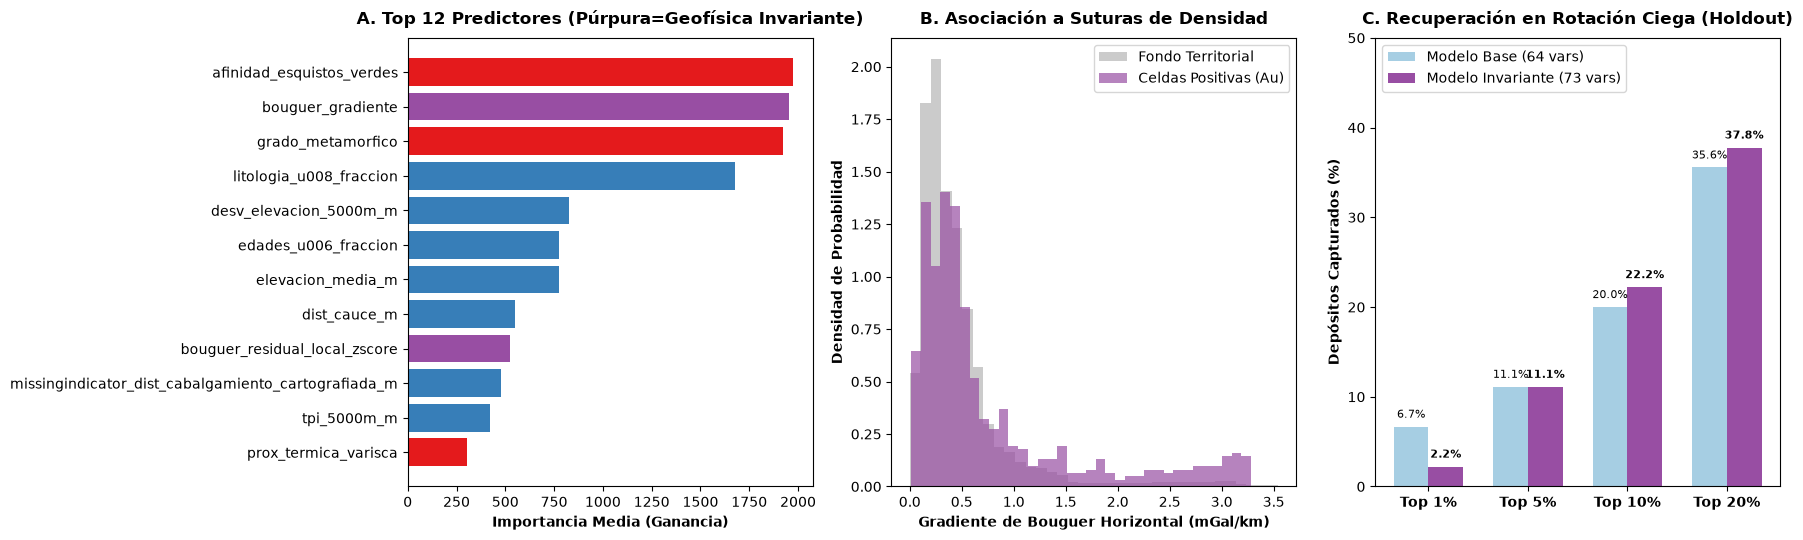

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=100)

# Panel 1: Top 12 Características
ax1 = axes[0]
top12 = df_imp.head(12).iloc[::-1]
col_map = {'Geofísica Invariante': '#984ea3', 'Física Superficial': '#e41a1c', 'Original': '#377eb8'}
bar_colors = [col_map[t] for t in top12['tipo']]
ax1.barh(top12['feature'], top12['importance'], color=bar_colors)
ax1.set_xlabel('Importancia Media (Ganancia)', fontweight='bold')
ax1.set_title('A. Top 12 Predictores (Púrpura=Geofísica Invariante)', fontweight='bold', pad=10)

# Panel 2: Histograma del Gradiente de Bouguer
ax2 = axes[1]
is_pos = grid.cell_id.isin(set(data.positives.cell_id))
ax2.hist(grid.loc[~is_pos, 'bouguer_gradiente'], bins=35, density=True, alpha=0.5, color='#999999', label='Fondo Territorial')
ax2.hist(grid.loc[is_pos, 'bouguer_gradiente'], bins=35, density=True, alpha=0.7, color='#984ea3', label='Celdas Positivas (Au)')
ax2.set_xlabel('Gradiente de Bouguer Horizontal (mGal/km)', fontweight='bold')
ax2.set_ylabel('Densidad de Probabilidad', fontweight='bold')
ax2.set_title('B. Asociación a Suturas de Densidad', fontweight='bold', pad=10)
ax2.legend()

# Panel 3: Comparativa de Recuperación Ciega
ax3 = axes[2]
met_bars = ['Top 1%', 'Top 5%', 'Top 10%', 'Top 20%']
orig_bars = [base_r01*100, base_r05*100, base_r10*100, base_r20*100]
new_bars = [summary_invar_rot['recovery_at_01']*100, summary_invar_rot['recovery_at_05']*100,
            summary_invar_rot['recovery_at_10']*100, summary_invar_rot['recovery_at_20']*100]

x = np.arange(len(met_bars))
w = 0.35
ax3.bar(x - w/2, orig_bars, width=w, label='Modelo Base (64 vars)', color='#a6cee3')
ax3.bar(x + w/2, new_bars, width=w, label='Modelo Invariante (73 vars)', color='#984ea3')
ax3.set_xticks(x)
ax3.set_xticklabels(met_bars, fontweight='bold')
ax3.set_ylabel('Depósitos Capturados (%)', fontweight='bold')
ax3.set_title('C. Recuperación en Rotación Ciega (Holdout)', fontweight='bold', pad=10)
ax3.set_ylim(0, 50)
for i in range(len(x)):
    ax3.text(x[i] - w/2, orig_bars[i] + 1, f"{orig_bars[i]:.1f}%", ha='center', fontsize=8)
    ax3.text(x[i] + w/2, new_bars[i] + 1, f"{new_bars[i]:.1f}%", ha='center', fontsize=8, fontweight='bold')
ax3.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [9]:
out_dir = ROOT / "reports" / "reentrenamiento_gravimetria_20261021"
out_dir.mkdir(parents=True, exist_ok=True)

df_export = pd.DataFrame({
    'cell_id': data.grid.cell_id.values,
    'favorability_invariante': score_ens,
    'bouguer_gradiente_mgal_km': grid['bouguer_gradiente'].values,
    'bouguer_residual_local_zscore': grid['bouguer_residual_local_zscore'].values
})
df_export.to_parquet(out_dir / "favorabilidad_nacional_gravimetria.parquet", index=False)
df_comp_rot.to_csv(out_dir / "comparativa_rotaciones_gravimetria.csv", index=False)
df_imp.to_csv(out_dir / "importancia_variables_gravimetria.csv", index=False)

print(f"✅ Artefactos del modelo con geofísica invariante guardados en: {out_dir}")

✅ Artefactos del modelo con geofísica invariante guardados en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_gravimetria_20261021
